In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
car_data = pd.read_csv("auto_imports.csv", header=None, na_values="?")

car_data.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [3]:
print("Number of Rows:", car_data.shape[0])
print("Number of Columns:", car_data.shape[1])

Number of Rows: 201
Number of Columns: 26


In [4]:
print(car_data.columns)

Index([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25],
      dtype='int64')


In [5]:
car_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       201 non-null    int64  
 1   1       164 non-null    float64
 2   2       201 non-null    object 
 3   3       201 non-null    object 
 4   4       201 non-null    object 
 5   5       199 non-null    object 
 6   6       201 non-null    object 
 7   7       201 non-null    object 
 8   8       201 non-null    object 
 9   9       201 non-null    float64
 10  10      201 non-null    float64
 11  11      201 non-null    float64
 12  12      201 non-null    float64
 13  13      201 non-null    int64  
 14  14      201 non-null    object 
 15  15      201 non-null    object 
 16  16      201 non-null    int64  
 17  17      201 non-null    object 
 18  18      197 non-null    float64
 19  19      197 non-null    float64
 20  20      201 non-null    float64
 21  21      199 non-null    float64
 22  22

In [6]:
column_names = [
    'symboling', 'normalized-losses', 'make', 'fuel-type',
    'aspiration', 'num-of-doors', 'body-style', 'drive-wheels',
    'engine-location', 'wheel-base', 'length', 'width',
    'height', 'curb-weight', 'engine-type', 'num-of-cylinders',
    'engine-size', 'fuel-system', 'bore', 'stroke',
    'compression-ratio', 'horsepower', 'peak-rpm',
    'city-mpg', 'highway-mpg', 'price'
]

car_data.columns = column_names

car_data.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [7]:
car_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               201 non-null    object 
 3   fuel-type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num-of-doors       199 non-null    object 
 6   body-style         201 non-null    object 
 7   drive-wheels       201 non-null    object 
 8   engine-location    201 non-null    object 
 9   wheel-base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb-weight        201 non-null    int64  
 14  engine-type        201 non-null    object 
 15  num-of-cylinders   201 non-null    object 
 16  engine-size        201 non

In [8]:
car_data.isnull().sum()

symboling             0
normalized-losses    37
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

In [9]:
missing_percentage = (car_data.isnull().sum() / len(car_data)) * 100

print(missing_percentage[missing_percentage > 0])

normalized-losses    18.407960
num-of-doors          0.995025
bore                  1.990050
stroke                1.990050
horsepower            0.995025
peak-rpm              0.995025
dtype: float64


In [10]:
numeric_columns = [
    'normalized-losses',
    'bore',
    'stroke',
    'horsepower',
    'peak-rpm'
]

for column in numeric_columns:
    car_data[column] = car_data[column].fillna(car_data[column].median())

In [11]:
car_data['num-of-doors'] = car_data['num-of-doors'].fillna(
    car_data['num-of-doors'].mode()[0]
)

In [12]:
car_data.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

In [13]:
print("Duplicate Rows:", car_data.duplicated().sum())

Duplicate Rows: 0


In [14]:
car_data.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,120.711443,98.797015,174.200995,65.889055,53.766667,2555.666667,126.875622,3.330299,3.257562,10.164279,103.313433,5118.407960,25.179104,30.686567,13207.129353
std,1.254802,32.111623,6.066366,12.322175,2.101471,2.447822,517.296727,41.546834,0.268088,0.316082,4.004965,37.374942,478.183493,6.423220,6.815150,7947.066342
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,101.000000,94.500000,166.800000,64.100000,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,2.000000,137.000000,102.400000,183.500000,66.600000,55.500000,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000
max,3.000000,256.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


In [15]:
categorical_columns = car_data.select_dtypes(include='object').columns

car_data[categorical_columns].describe()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system
count,201,201,201,201,201,201,201,201,201,201
unique,22,2,2,2,5,3,2,6,7,8
top,toyota,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,32,181,165,115,94,118,198,145,157,92


In [16]:
car_data['make'].value_counts()

make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
volkswagen       12
subaru           12
peugot           11
volvo            11
dodge             9
mercedes-benz     8
bmw               8
plymouth          7
audi              6
saab              6
porsche           4
jaguar            3
chevrolet         3
alfa-romero       3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

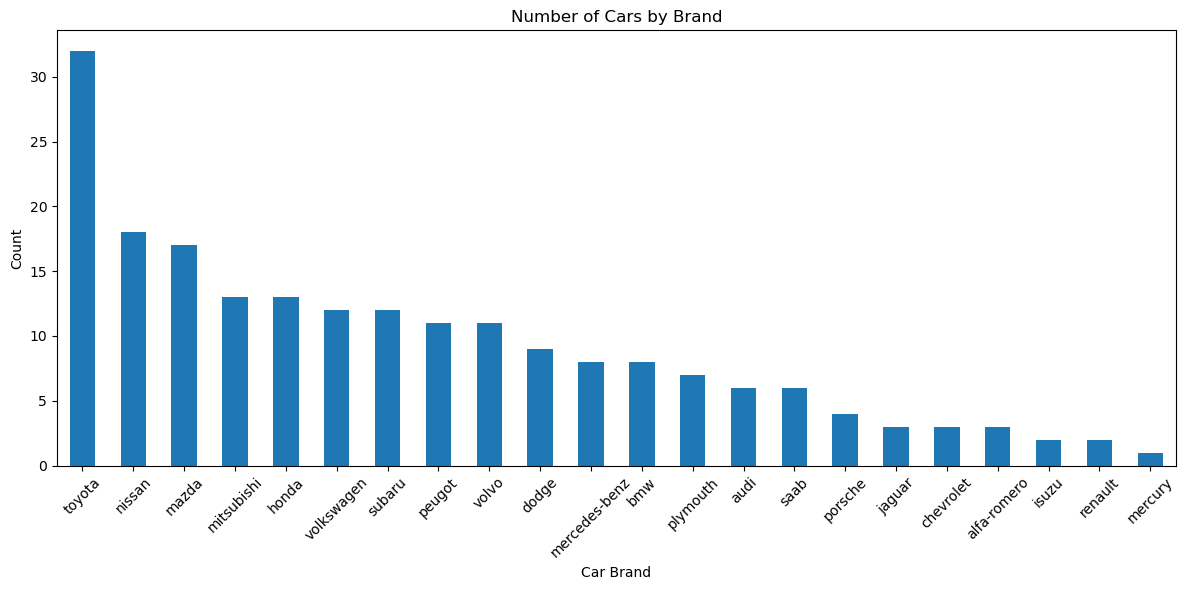

In [17]:
plt.figure(figsize=(12, 6))

car_data['make'].value_counts().plot(kind='bar')

plt.title('Number of Cars by Brand')
plt.xlabel('Car Brand')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

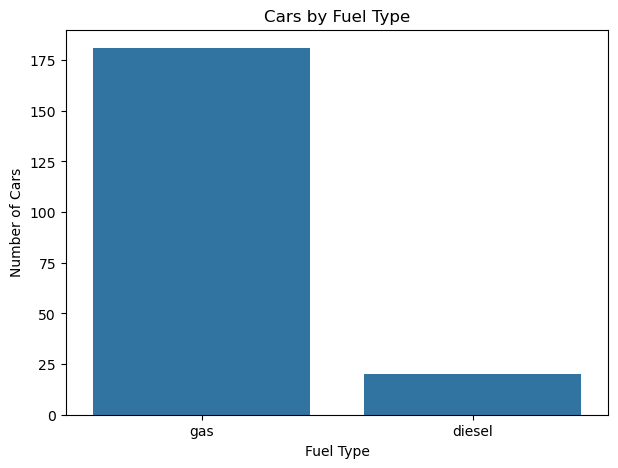

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(data=car_data, x='fuel-type')

plt.title('Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.show()

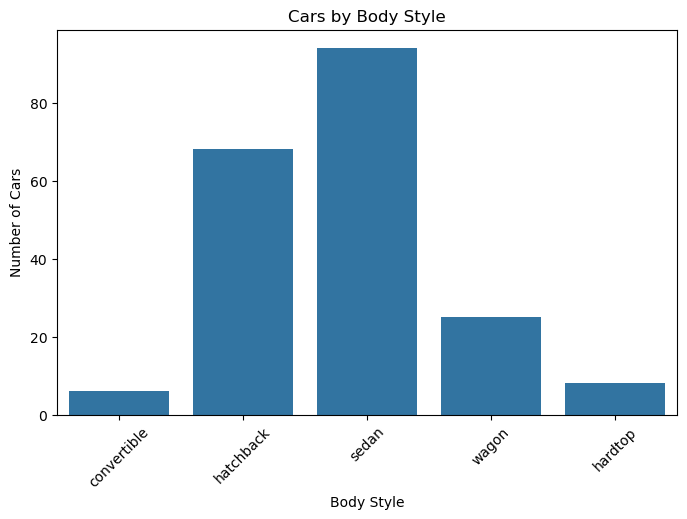

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(data=car_data, x='body-style')

plt.title('Cars by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)
plt.show()

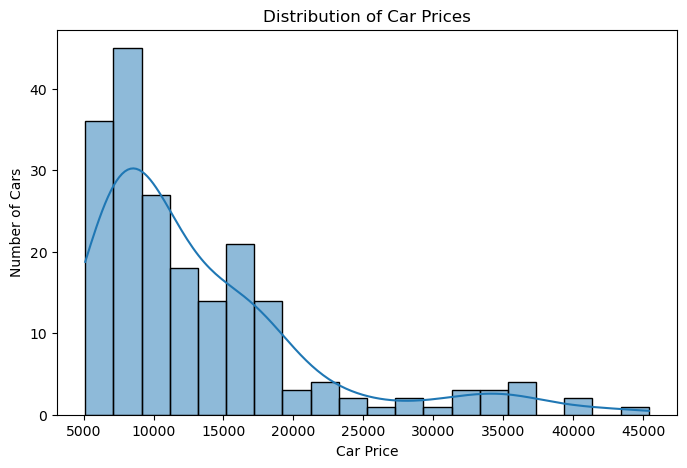

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(data=car_data, x='price', bins=20, kde=True)

plt.title('Distribution of Car Prices')
plt.xlabel('Car Price')
plt.ylabel('Number of Cars')
plt.show()

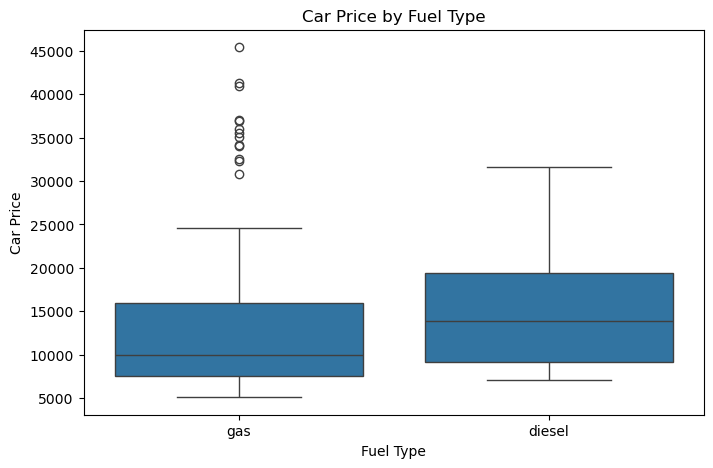

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=car_data, x='fuel-type', y='price')

plt.title('Car Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Car Price')
plt.show()

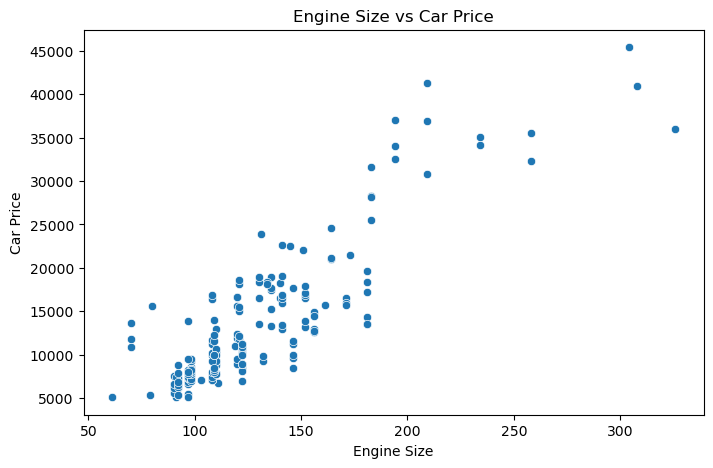

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=car_data, x='engine-size', y='price')

plt.title('Engine Size vs Car Price')
plt.xlabel('Engine Size')
plt.ylabel('Car Price')
plt.show()

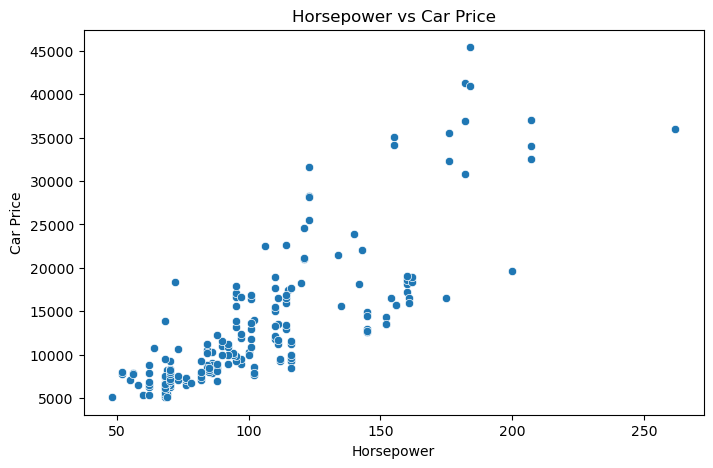

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=car_data, x='horsepower', y='price')

plt.title('Horsepower vs Car Price')
plt.xlabel('Horsepower')
plt.ylabel('Car Price')
plt.show()

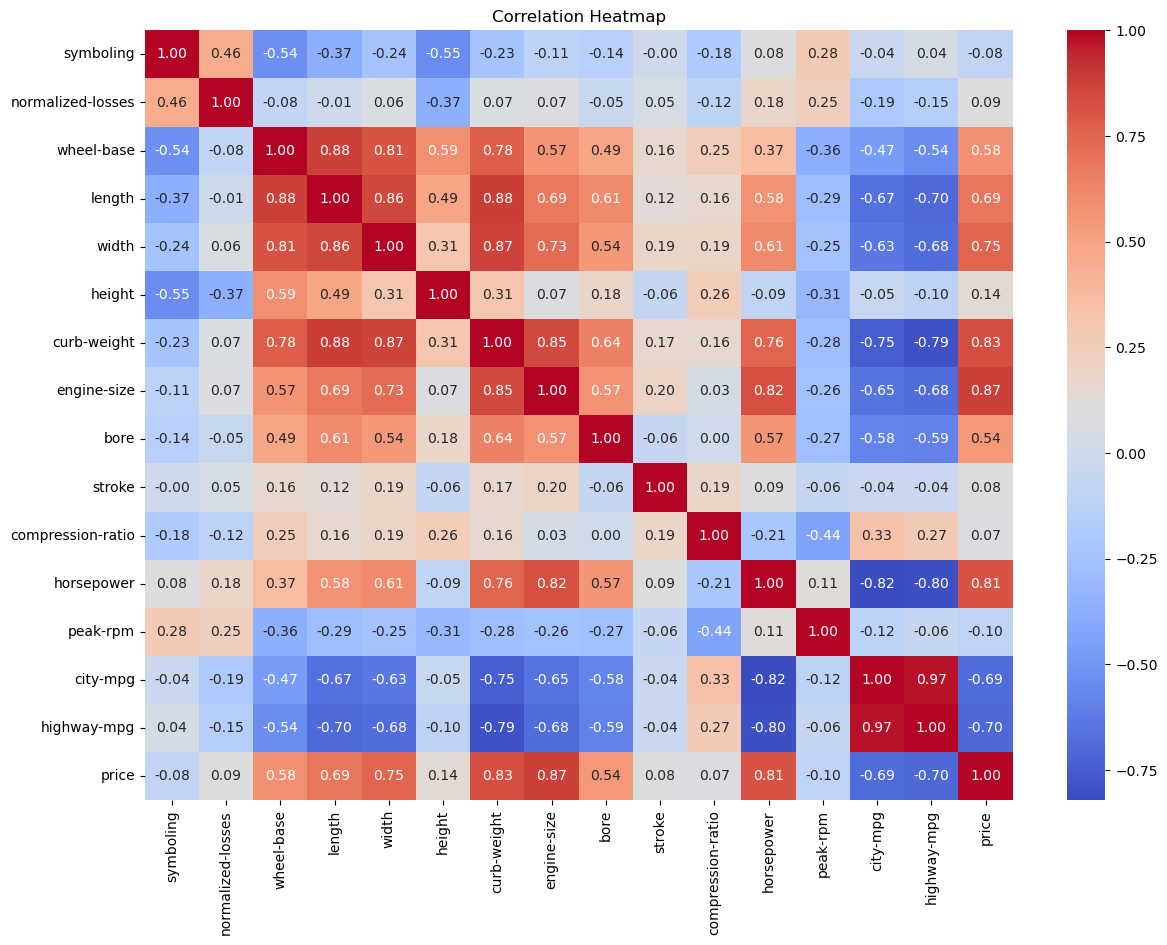

In [24]:
plt.figure(figsize=(14, 10))

numeric_data = car_data.select_dtypes(include=np.number)

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [25]:
X = car_data.drop('price', axis=1)
y = car_data['price']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (201, 25)
Target Shape: (201,)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 25)
Testing Data: (41, 25)


In [27]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_test = X_train.align(
    X_test, join='left', axis=1, fill_value=0
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (160, 64)
Testing Shape: (41, 64)


In [28]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression Model Training Completed!")

Linear Regression Model Training Completed!


In [29]:
lr_predictions = lr_model.predict(X_test)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(lr_predictions[:10])

First 10 Actual Prices:
[ 8249 41315  6855  9258 11850  5572 35056  9988 15998 35550]

First 10 Predicted Prices:
[ 7307.84469261 22154.72570112  6612.23242193  7461.60114972
 12921.11551251  5564.11482863 43457.28063981  9672.30235097
 16329.79263941 32386.8250434 ]


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, lr_predictions)
mse = mean_squared_error(y_test, lr_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, lr_predictions)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 2377.030047383865
MSE: 18385247.159532722
RMSE: 4287.802136238649
R2 Score: 0.8497283851768862


In [31]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Training Completed!")

Decision Tree Model Training Completed!


In [32]:
dt_predictions = dt_model.predict(X_test)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(dt_predictions[:10])

First 10 Actual Prices:
[ 8249 41315  6855  9258 11850  5572 35056  9988 15998 35550]

First 10 Predicted Prices:
[ 6692. 30760.  6479.  8358. 13950.  5389. 32250. 11248. 16558. 32250.]


In [33]:
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_mse = mean_squared_error(y_test, dt_predictions)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_predictions)

print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

MAE: 1960.3048780487804
MSE: 8627198.49390244
RMSE: 2937.209303727339
R2 Score: 0.9294856882896969


In [34]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [35]:
rf_predictions = rf_model.predict(X_test)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(rf_predictions[:10])

First 10 Actual Prices:
[ 8249 41315  6855  9258 11850  5572 35056  9988 15998 35550]

First 10 Predicted Prices:
[ 7131.11833333 30646.22        6231.63        8055.71
 13404.40333333  5878.23       34406.94       10932.53
 17403.59       33479.38      ]


In [36]:
rf_predictions = rf_model.predict(X_test)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(rf_predictions[:10])

First 10 Actual Prices:
[ 8249 41315  6855  9258 11850  5572 35056  9988 15998 35550]

First 10 Predicted Prices:
[ 7131.11833333 30646.22        6231.63        8055.71
 13404.40333333  5878.23       34406.94       10932.53
 17403.59       33479.38      ]


In [37]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Model Evaluation")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Model Evaluation
MAE: 1953.9395325203254
MSE: 9227355.825205369
RMSE: 3037.6563046541933
R2 Score: 0.924580308963531


In [38]:
model_comparision = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAAE": [mae, dt_mae, rf_mae],
    "RMSE": [rmse, dt_rmse, rf_rmse],
    "R2 Score": [r2, dt_r2, rf_r2]
})

model_comparision

,Model,MAAE,RMSE,R2 Score
0,Linear Regression,2377.030047,4287.802136,0.849728
1,Decision Tree,1960.304878,2937.209304,0.929486
2,Random Forest,1953.939533,3037.656305,0.924580


In [39]:
best_model = model_comparision.loc[
    model_comparision["RMSE"].idxmin()
]

print("Best Model:", best_model["Model"])
print("Best RMSE:", best_model["RMSE"])
print("Best R2 Score:", best_model["R2 Score"])

Best Model: Decision Tree
Best RMSE: 2937.209303727339
Best R2 Score: 0.9294856882896969


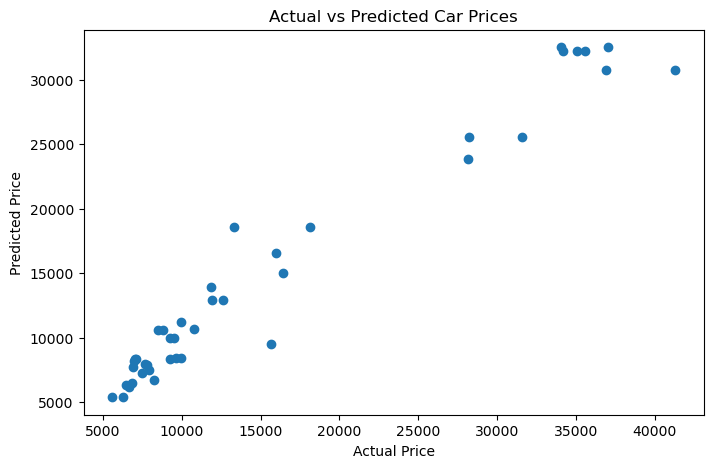

In [40]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, dt_predictions)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

curb-weight          0.583900
engine-size          0.283352
width                0.043894
bore                 0.019420
make_bmw             0.017327
horsepower           0.016621
normalized-losses    0.007340
height               0.006742
stroke               0.005801
compression-ratio    0.003960
dtype: float64


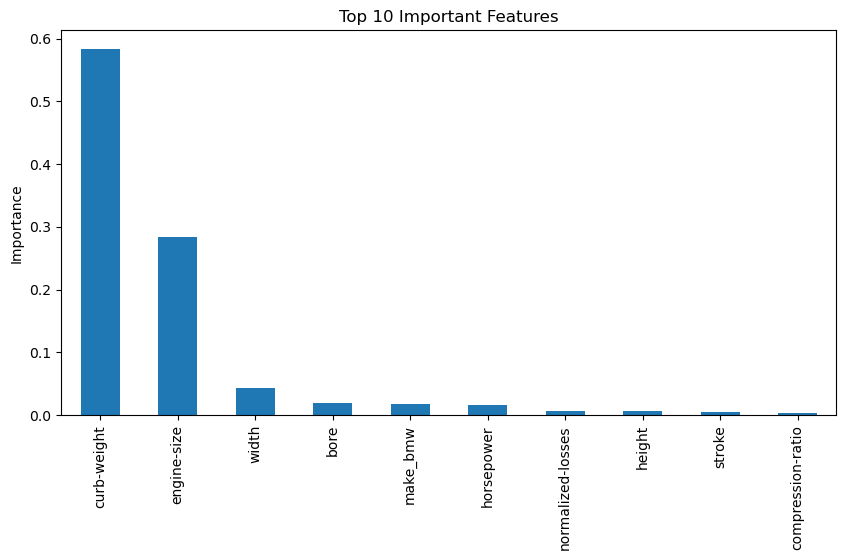

In [41]:
feature_importance = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

print(feature_importance.head(10))

feature_importance.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Important Features"
)

plt.ylabel("Importance")
plt.show()

## Challenges Faced Report

### 1. Missing Values
Some columns contained missing values. These missing values were handled during data preprocessing.

### 2. Categorical Data
The dataset contained categorical values such as car make, fuel type and body style. One-Hot Encoding was used to convert them into numerical values.

### 3. Dataset Size
The dataset contained only 201 records. This limited the amount of data available for model training.

### 4. Model Comparison
Three regression models were used:
- Linear Regression
- Decision Tree
- Random Forest

Their performance was compared using MAE, RMSE and R2 Score.

### 5. Feature Alignment
Training and testing datasets needed matching columns after encoding. The columns were aligned to avoid prediction errors.

### Conclusion
The challenges were handled through data preprocessing, encoding and model evaluation.

## Management Conclusion

The car price prediction analysis was performed using three machine learning models: Linear Regression, Decision Tree and Random Forest.

The Decision Tree model achieved the lowest RMSE and highest R2 Score among the three models.

The analysis helps management understand the relationship between car features and their prices.

Important features identified through feature importance analysis can help management make better decisions about car design, pricing strategies and business planning.

The predictive model can support price estimation for cars in the market.